In [97]:
import numpy as np
import metpy.constants as const

print(const.dry_air_gas_constant)
print(const.dry_air_spec_heat_press)
print(const.dry_air_spec_heat_press/const.dry_air_gas_constant)

hgt_urb=20.
frc_urb=0.63
lp_urb=np.array([0.10,0.20,0.30,0.40])
lb_urb=np.array([0.3,0.6,0.9,1.2])
bw=np.zeros(4)
sw=np.zeros(4)

bw[:]=2.*hgt_urb*lp_urb[:]/(lb_urb[:]-lp_urb[:])
sw[:]=2.*hgt_urb*lp_urb[:]*(frc_urb/lp_urb[:]-1.)/(lb_urb[:]-lp_urb[:]) 

print(bw)
print(sw)

287.04749097718457 joule / kelvin / kilogram
1004.6662184201462 joule / kelvin / kilogram
3.5000000000000004 dimensionless
[20. 20. 20. 20.]
[106.   43.   22.   11.5]


<xarray.DataArray 'latlon' ()> Size: 8B
array(45.43009288)
Coordinates:
    xy_coord  object 8B CoordPair(x=138, y=140)
    lat_lon   <U3 12B 'lat' <xarray.DataArray 'latlon' ()> Size: 8B
array(9.14715206)
Coordinates:
    xy_coord  object 8B CoordPair(x=138, y=140)
    lat_lon   <U3 12B 'lon'
lb 0.7827551
lp 0.2412245
hgt_urb 18.586632
frc_urb 0.63133305
ws 26.778927605162746
bs 16.558808811815556
[[ 7.408783   7.4217224  7.434662  ... 11.259613  11.272583  11.285553 ]
 [ 7.408142   7.4210815  7.434021  ... 11.2595825 11.272583  11.285553 ]
 [ 7.407501   7.4204407  7.4334106 ... 11.2595825 11.2725525 11.285553 ]
 ...
 [ 7.210327   7.223938   7.2375183 ... 11.255554  11.269165  11.282806 ]
 [ 7.2096252  7.223236   7.2368164 ... 11.255524  11.269165  11.282806 ]
 [ 7.2089233  7.222534   7.2361145 ... 11.255524  11.269165  11.282776 ]] [[44.077988 44.07845  44.0789   ... 44.147278 44.147285 44.147297]
 [44.08729  44.087746 44.0882   ... 44.15659  44.1566   44.156605]
 [44.096584 44.09704

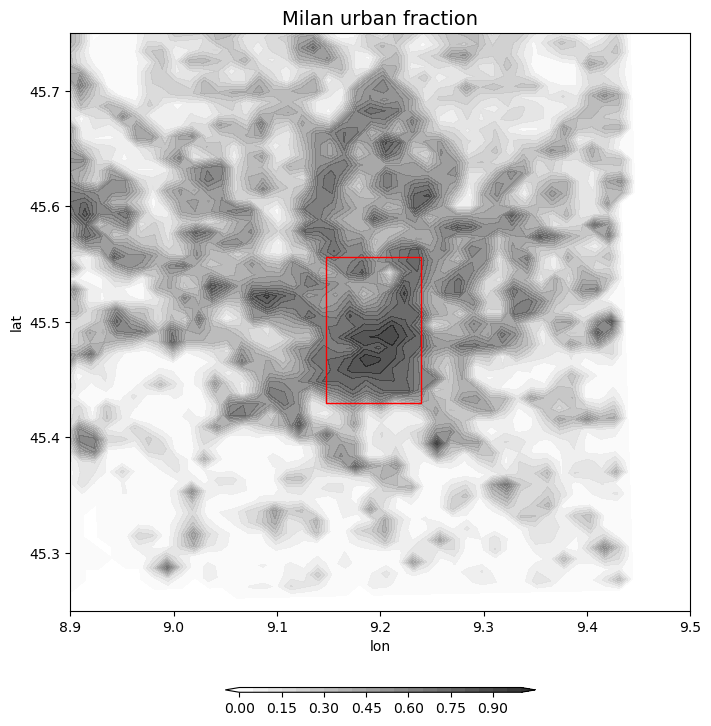

In [98]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
#import cartopy.crs as ccrs
import matplotlib as mpl
from netCDF4 import Dataset
from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, ll_to_xy,xy_to_ll)
#Milan
s=xr.open_dataset("/glade/u/home/fdemartin/transfer/met_em.d03.2023-07-24_08:00:00.nc", engine="netcdf4")

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]

x_0=138
y_0=140

ncfile = Dataset("/glade/u/home/fdemartin/transfer/met_em.d03.2023-07-24_08:00:00.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
print(lat0,lon0)
delta_y=14
delta_x=7
#140:154,138:145

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

#x=np.arange(0,np.shape(frc_urb_all,axis=
print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 


print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]
#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,300,1)
y=np.arange(0,300,1)

levels=np.linspace(0,1,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Milan urban fraction',loc='center',fontsize=14)
ax.set_ylim(45.25,45.75)
ax.set_xlim(8.9,9.5)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

print(to_np(lon),to_np(lat))
ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0132, delta_y*0.009,
             fill=None, lw=1, edgecolor='red', rotation_point='xy'))

figname='/glade/u/home/fdemartin/plot/cities/Milan'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.30682224
lp 0.10786667
hgt_urb 8.3902
frc_urb 0.42046666
ws 26.365448490869976
bs 9.097738699107518


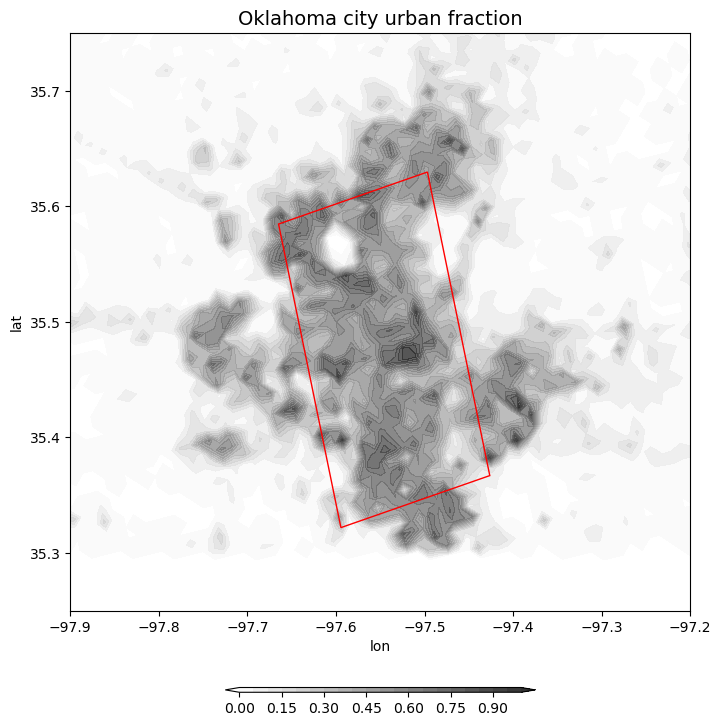

In [99]:
#OKC
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/OKC.nc", engine="netcdf4")

x_0=151
y_0=120
delta_y=30
delta_x=15

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/OKC.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Oklahoma city urban fraction',loc='center',fontsize=14)
ax.set_ylim(35.25,35.75)
ax.set_xlim(-97.9,-97.2)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0116, delta_y*0.00907,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=15))#np.rad2deg(20)))

figname='/glade/u/home/fdemartin/plot/cities/OK'
fig.savefig(figname+'.png',bbox_inches='tight')

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Okla city',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(100,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# # ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
# #              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

# figname='/glade/u/home/fdemartin/plot/cities/OK'
# fig.savefig(figname+'.png',bbox_inches='tight')

In [100]:
#LA
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/LA.nc", engine="netcdf4")

x_0=146
y_0=112
delta_y=13
delta_x=10

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=153
y_02=117
delta_y2=2
delta_x2=2

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['URB_PARAM'][0,93,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,100,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Atlanta',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')


lb 0.8732308
lp 0.30415383
hgt_urb 11.195769
frc_urb 0.8943077
ws 23.22085237825418
bs 11.967575649840029
lb 1.5925
lp 0.35999995
hgt_urb 60.6275
frc_urb 0.93249995
ws 56.32330927162155
bs 35.417274495993894


lb 0.61499995
lp 0.18374999
hgt_urb 20.544
frc_urb 0.51175
ws 31.25070279136261
bs 17.507061291584662


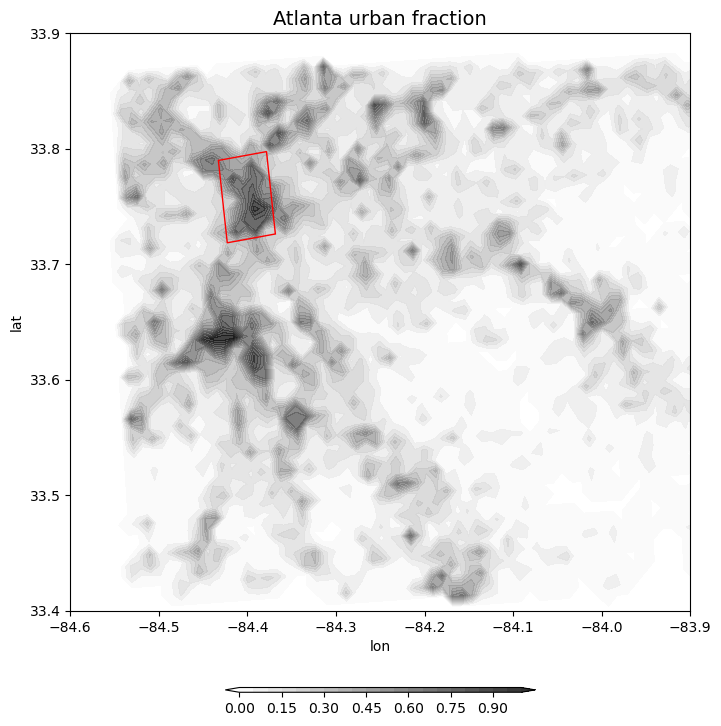

In [101]:
#ATL
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/ATL.nc", engine="netcdf4")

x_0=137
y_0=157
delta_y=8
delta_x=5

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/ATL.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)


# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Atlanta',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

# figname='/glade/u/home/fdemartin/plot/cities/Atl'
# fig.savefig(figname+'.png',bbox_inches='tight')

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Atlanta urban fraction',loc='center',fontsize=14)
ax.set_ylim(33.4,33.9)
ax.set_xlim(-84.6,-83.9)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.01097, delta_y*0.00900,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=8))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/ATL_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.71559995
lp 0.22937776
hgt_urb 9.202422
frc_urb 0.6798666
ws 17.052238391168707
bs 8.68257746520645
lb 2.455
lp 0.28
hgt_urb 114.5275
frc_urb 0.7525
ws 49.760223849581166
bs 29.487540059011064


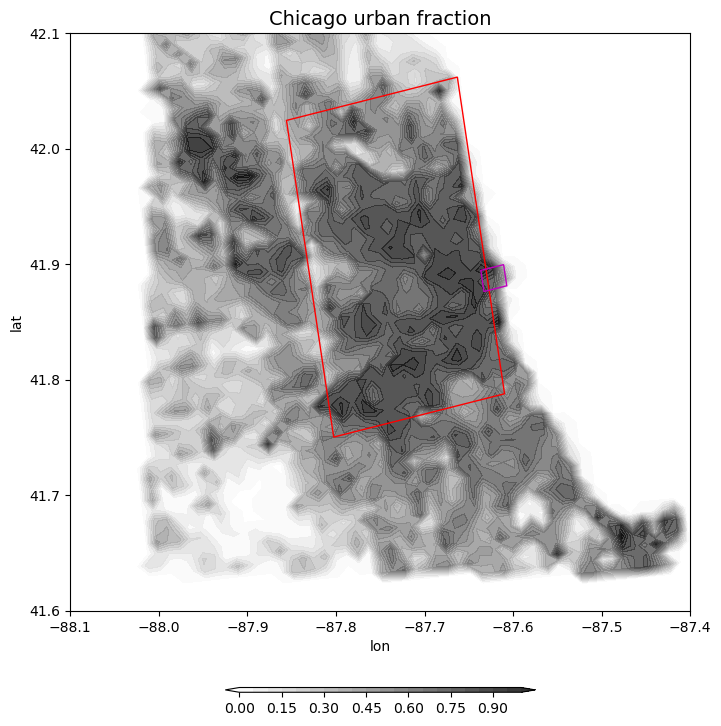

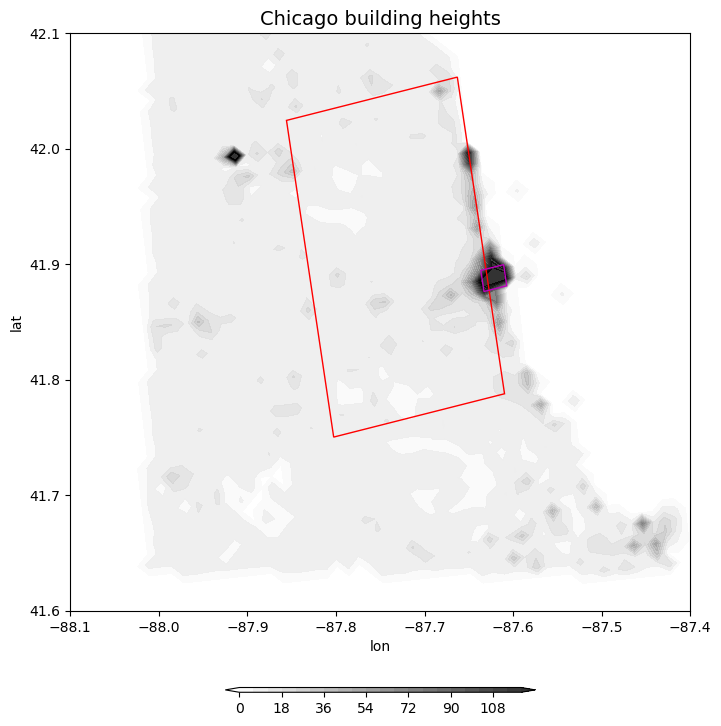

In [102]:
#CHI
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/CHI.nc", engine="netcdf4")

x_0=142
y_0=135
delta_y=30
delta_x=15

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/CHI.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=157
y_02=147
delta_y2=2
delta_x2=2

lat02,lon02 = xy_to_ll(ncfile,x_02,y_02)

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]
hb=s['URB_PARAM'][0,93,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Chicago',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

levels=np.linspace(0,1,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Chicago urban fraction',loc='center',fontsize=14)
ax.set_ylim(41.6,42.1)
ax.set_xlim(-88.1,-87.4)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0131, delta_y*0.00931,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=11))#np.rad2deg(20)))
ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
             fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=11))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/CHI_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')

levels=np.linspace(0,120,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Chicago building heights',loc='center',fontsize=14)
ax.set_ylim(41.6,42.1)
ax.set_xlim(-88.1,-87.4)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(to_np(lon), to_np(lat), to_np(hb), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0131, delta_y*0.00931,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=11))#np.rad2deg(20)))
ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
             fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=11))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/CHI_hb'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.43631577
lp 0.15842105
hgt_urb 11.355
frc_urb 0.47013158
ws 25.473479542857
bs 12.946420154033975
lb 0.84999996
lp 0.185
hgt_urb 45.262497
frc_urb 0.8274999
ws 87.4621097025471
bs 25.183646687756234


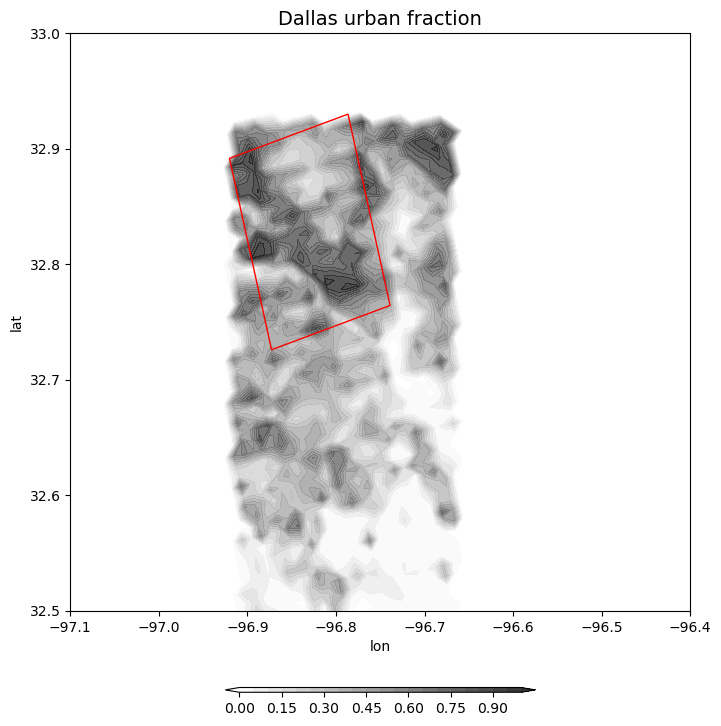

In [103]:
#DAL
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/DAL.nc", engine="netcdf4")

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/DAL.nc")

x_0=138
y_0=170
delta_y=19
delta_x=12

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=145
y_02=174
delta_y2=2
delta_x2=2

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Dallas',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Dallas urban fraction',loc='center',fontsize=14)
ax.set_ylim(32.5,33)
ax.set_xlim(-97.1,-96.4)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0116, delta_y*0.00907,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=16))#np.rad2deg(20)))
# ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
#              fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=11))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/DAL_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.29
lp 0.111714266
hgt_urb 11.895
frc_urb 0.4924286
ws 50.80156993108793
bs 14.906872667587095
lb 0.0
lp 0.0
hgt_urb 2.84
frc_urb 0.0
ws nan
bs nan


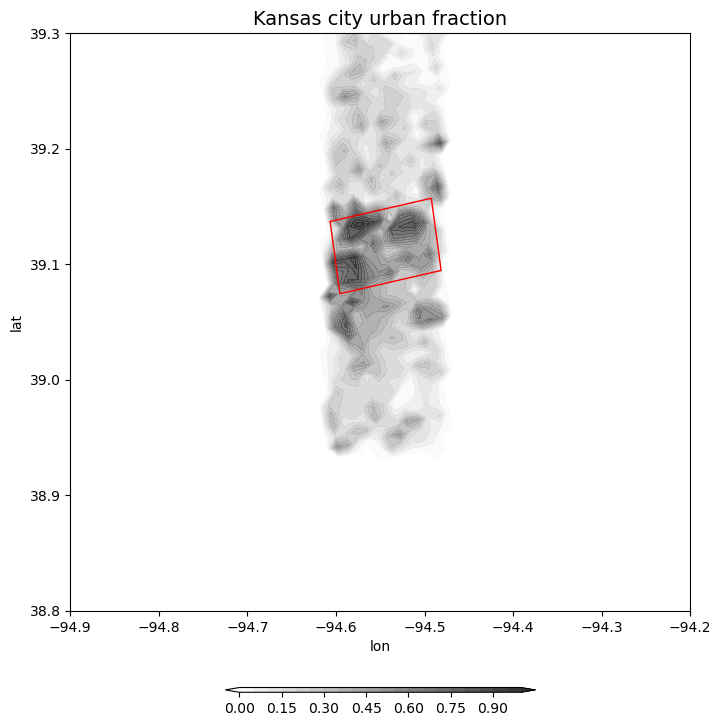

In [104]:
#KSC
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/KSC.nc", engine="netcdf4")

x_0=128
y_0=138
delta_y=7
delta_x=10

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/KSC.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=145
y_02=174
delta_y2=2
delta_x2=2

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Kansas city',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Kansas city urban fraction',loc='center',fontsize=14)
ax.set_ylim(38.8,39.3)
ax.set_xlim(-94.9,-94.2)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0116, delta_y*0.00907,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=10))#np.rad2deg(20)))
# ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
#              fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=11))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/KSC_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.75405127
lp 0.20238459
hgt_urb 19.854948
frc_urb 0.6224103
ws 30.234158564092382
bs 14.567983562386155
lb 1.1227777
lp 0.22277778
hgt_urb 44.072918
frc_urb 0.6472222
ws 41.5700124052564
bs 21.818817549658927


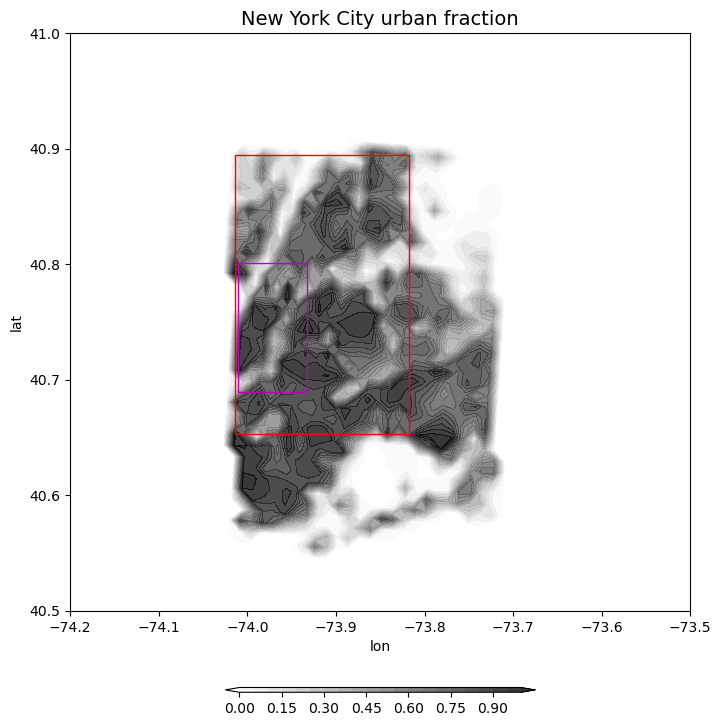

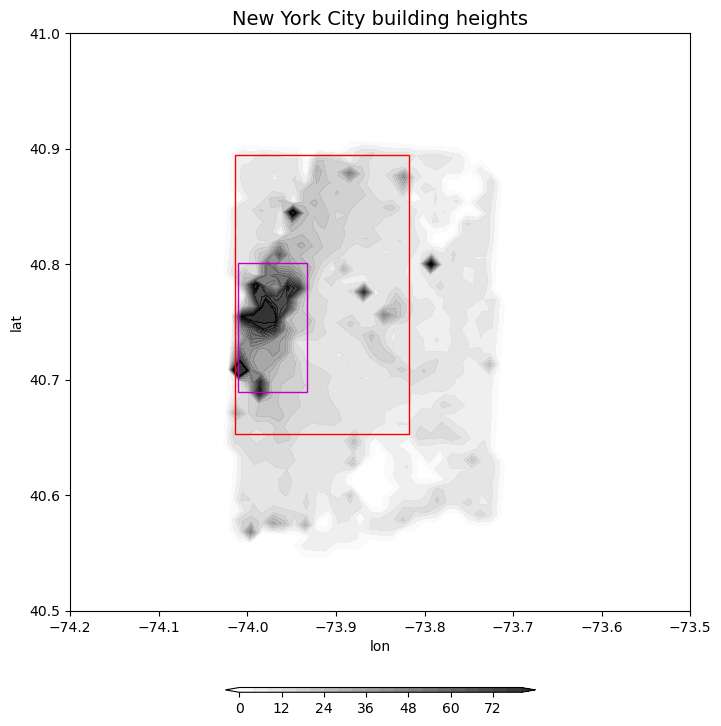

In [105]:
#NYC
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/NYC.nc", engine="netcdf4")

x_0=123
y_0=135
delta_y=26 #15
delta_x=15 #22

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/NYC.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=123
y_02=139
delta_y2=12
delta_x2=6

lat02,lon02 = xy_to_ll(ncfile,x_02,y_02)

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

hb=s['URB_PARAM'][0,93,:,:]
frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('New York city',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(120,200)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

levels=np.linspace(0,1,num=21)
fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('New York City urban fraction',loc='center',fontsize=14)
ax.set_ylim(40.5,41.0)
ax.set_xlim(-74.2,-73.5)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0131, delta_y*0.00931,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=0))#np.rad2deg(20)))
ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
             fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=0))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/NYC_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')

levels=np.linspace(0,80,num=21)
fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('New York City building heights',loc='center',fontsize=14)
ax.set_ylim(40.5,41.0)
ax.set_xlim(-74.2,-73.5)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(hb), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.0131, delta_y*0.00931,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=0))#np.rad2deg(20)))
ax.add_patch(mpl.patches.Rectangle((to_np(lon02),to_np(lat02)), delta_x2*0.0131, delta_y2*0.00931,
             fill=None, lw=1, edgecolor='m', rotation_point='xy',angle=0))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/NYC_hb'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.6109091
lp 0.1753247
hgt_urb 15.559608
frc_urb 0.5042857
ws 23.501777589446775
bs 12.525624971873581
lb 0.82624996
lp 0.22375
hgt_urb 30.028748
frc_urb 0.60249996
ws 37.753985115142726
bs 22.303510534283248


/glade/derecho/scratch/fdemartin/tmp/ipykernel_23985/2665291070.py:78: UserWarning: The following kwargs were not used by contour: 'cmpa'
  cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)


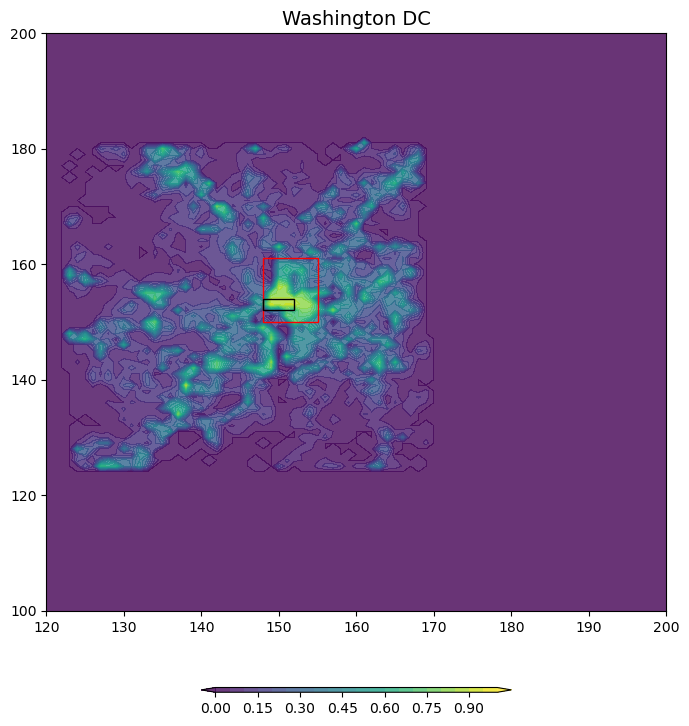

In [106]:
#DC
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/DC.nc", engine="netcdf4")

x_0=148
y_0=150
delta_y=11 #15
delta_x=7 #22

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=148
y_02=152
delta_y2=2
delta_x2=4

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Washington DC',loc='center',fontsize=14)
ax.set_ylim(100,200)
ax.set_xlim(120,200)
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
             fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

figname='/glade/u/home/fdemartin/plot/cities/DC'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.94619995
lp 0.182
hgt_urb 16.624866
frc_urb 0.4146
ws 10.12024136959649
bs 7.918675082957981
lb 0.0
lp 0.0
hgt_urb 0.0
frc_urb 0.0
ws nan
bs nan


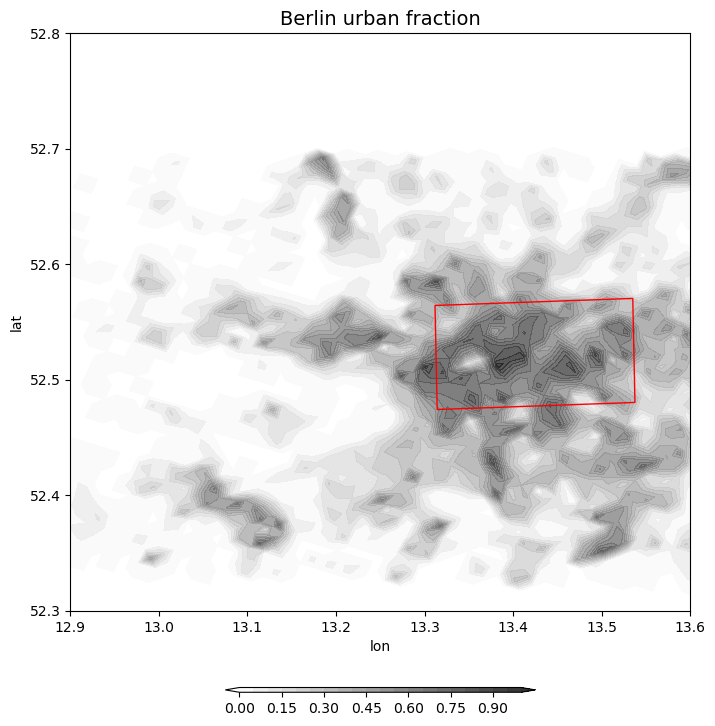

In [107]:
#Berlin
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/BER.nc", engine="netcdf4")

x_0=110 #112 nel reference x-y
y_0=160 #155 nel reference x-y
delta_y=15 #15
delta_x=10 #22

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/BER.nc")

lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
# 120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=148
y_02=152
delta_y2=2
delta_x2=4

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

hb=s['URB_PARAM'][0,93,:,:]
frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Berlin',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(80,180)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Berlin urban fraction',loc='center',fontsize=14)
ax.set_ylim(52.3,52.8)
ax.set_xlim(12.9,13.6)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_y*0.01489, -delta_x*0.00901,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.radians(90)))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/BER'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.43934998
lp 0.13029999
hgt_urb 8.666975
frc_urb 0.37875
ws 13.935027768463371
bs 7.308246184420117
lb 1.2041667
lp 0.30666664
hgt_urb 28.635834
frc_urb 0.73708326
ws 27.46593358731226
bs 19.569146769863735


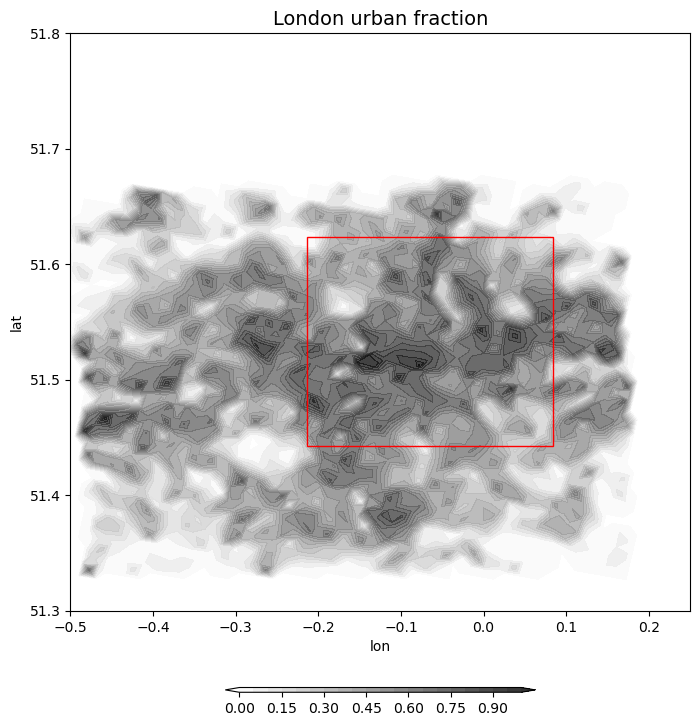

In [108]:
#London
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/LON.nc", engine="netcdf4")

x_0=108 #112
y_0=157 #148
delta_y=20 #15
delta_x=20 #22

ncfile = Dataset("/glade/work/fdemartin/wpsv4.6.0/LON.nc")
lat0,lon0 = xy_to_ll(ncfile,x_0,y_0)
lat=s['XLAT_M'][0,:,:]
lon=s['XLONG_M'][0,:,:]

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
# 120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=120
y_02=153
delta_y2=6
delta_x2=4

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

# fig=plt.figure(figsize=(8, 10))
# #print(str(times[i,0])[11:16])

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Berlin',loc='center',fontsize=14)
# ax.set_ylim(100,200)
# ax.set_xlim(80,180)
# #cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
# cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

# cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

# ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
#              fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

# figname='/glade/u/home/fdemartin/plot/cities/Milan'
# fig.savefig(figname+'.png',bbox_inches='tight')

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('London urban fraction',loc='center',fontsize=14)
ax.set_ylim(51.3,51.8)
ax.set_xlim(-0.5,0.25)
ax.set_xlabel('lon')
ax.set_ylabel('lat')
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())

cf = ax.contourf(to_np(lon), to_np(lat), to_np(frc_urb_all), levels=levels, cmap='binary', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

# ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
#              fill=None, lw=1, edgecolor='red', rotation_point='xy'))

ax.add_patch(mpl.patches.Rectangle((to_np(lon0),to_np(lat0)), delta_x*0.01489, -delta_y*0.00901,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=0))#np.rad2deg(20)))


figname='/glade/u/home/fdemartin/plot/cities/LON'
fig.savefig(figname+'.png',bbox_inches='tight')

lb 0.33997497
lp 0.102825
hgt_urb 8.977099
frc_urb 0.62295
ws 39.37773091352849
bs 7.78469641410647
lb 1.1978749
lp 0.329125
hgt_urb 27.597626
frc_urb 0.44174996
ws 7.155527408012326
bs 20.91066264480161


/glade/derecho/scratch/fdemartin/tmp/ipykernel_23985/3265911348.py:78: UserWarning: The following kwargs were not used by contour: 'cmpa'
  cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)


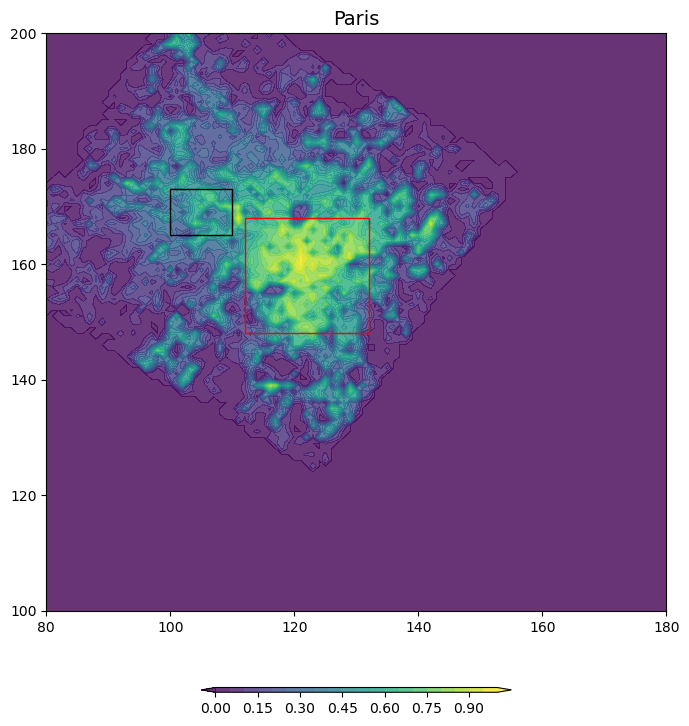

In [109]:
#Paris
s=xr.open_dataset("/glade/work/fdemartin/wpsv4.6.0/PAR.nc", engine="netcdf4")

x_0=112
y_0=148
delta_y=20 #15
delta_x=20 #22

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_0:y_0+delta_y,x_0:x_0+delta_x] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_0:y_0+delta_y,x_0:x_0+delta_x]
lb_urb=s['URB_PARAM'][:,94,y_0:y_0+delta_y,x_0:x_0+delta_x]
frc_urb=s['FRC_URB2D'][:,y_0:y_0+delta_y,x_0:x_0+delta_x]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#smaller box

x_02=100
y_02=165
delta_y2=8
delta_x2=10

# lp_urb=s['URB_PARAM'][:,90,138:145,141:148] #135:147,140:157
# hgt_urb=s['URB_PARAM'][:,93,138:145,141:148]
# lb_urb=s['URB_PARAM'][:,94,138:145,141:148]
# frc_urb=s['FRC_URB2D'][:,138:145,141:148]
#120:150,151:166

lp_urb=s['URB_PARAM'][:,90,y_02:y_02+delta_y2,x_02:x_02+delta_x2] #y,x 
hgt_urb=s['URB_PARAM'][:,93,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
lb_urb=s['URB_PARAM'][:,94,y_02:y_02+delta_y2,x_02:x_02+delta_x2]
frc_urb=s['FRC_URB2D'][:,y_02:y_02+delta_y2,x_02:x_02+delta_x2]

bs=2.*np.mean(hgt_urb)*np.mean(lp_urb)/(np.mean(lb_urb)-np.mean(lp_urb))
ws=2.*np.mean(hgt_urb)*np.mean(lp_urb)*((np.mean(frc_urb)/np.mean(lp_urb))-1.)/(np.mean(lb_urb)-np.mean(lp_urb)) 

print("lb",np.mean(lb_urb).values)
print("lp",np.mean(lp_urb).values)
print("hgt_urb",np.mean(hgt_urb).values)
print("frc_urb",np.mean(frc_urb).values)
print("ws",ws.values)
print("bs",bs.values)

#plot figure########################

frc_urb_all=s['FRC_URB2D'][0,:,:]

#var1_dat = getvar(wrf_files, "FRC_URB2D",timeidx=0)
#lats, lons = latlon_coords(var1_dat)

x=np.arange(0,249,1)
y=np.arange(0,249,1)

levels=np.linspace(0,1,num=21)

fig=plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])

ax = fig.add_subplot(1, 1, 1)
ax.set_title('Paris',loc='center',fontsize=14)
ax.set_ylim(100,200)
ax.set_xlim(80,180)
#cf = ax.contourf(to_np(lats), to_np(lons), to_np(var1_dat), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8,transform=ccrs.PlateCarree())
cf = ax.contourf(x, y, to_np(frc_urb_all), levels=levels, cmpa='viridis_r', extend='both',alpha=0.8)

cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

ax.add_patch(mpl.patches.Rectangle((x_0,y_0), delta_x, delta_y,
             fill=None, lw=1, edgecolor='red', rotation_point='xy',angle=np.rad2deg(0)))

ax.add_patch(mpl.patches.Rectangle((x_02,y_02), delta_x2, delta_y2,
             fill=None, lw=1, edgecolor='black', rotation_point='xy',angle=np.rad2deg(0)))

figname='/glade/u/home/fdemartin/plot/cities/Paris_urbfrc'
fig.savefig(figname+'.png',bbox_inches='tight')